<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/BoxBehnkenOptimum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Optimal extraction conditions from the Box-Behnken response surface (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{X}$, $\mathbf{y}$ | `X`, `y` | design matrix and measured yields |
| $\hat{\theta}$ | `theta_hat` | parameter estimates |
| $y(\mathbf{x},\hat{\theta})=\mathbf{x}^T\hat{\theta}$ | `y_model(x)` | predicted yield |
| $\mathbf{x}^*$ | `x_star` | conditions of maximum predicted yield |
| $\mathbb{V}[y(\mathbf{x})]=\mathbf{x}^T\mathrm{Cov}[\hat{\theta}]\mathbf{x}$ | `V_y` | variance of the prediction |

**Note:** This notebook reproduces the response-surface optimum of the slides: fit the quadratic model to the Box-Behnken data, maximize the predicted yield, and quantify the uncertainty of that prediction.

**The concept.** Once the quadratic model is fitted, it replaces the process: we search the model for the conditions of largest yield. Two questions follow.

1. *Where is the optimum?* Solve $\max_{\mathbf{x}\in[-1,1]^3}\;y(\mathbf{x},\hat{\theta})$.
2. *How much should we trust it?* The estimate $\hat{\theta}$ is uncertain, so the prediction is uncertain too. Because $y(\mathbf{x},\hat{\theta})=\mathbf{x}^T\hat{\theta}$ is linear in $\hat{\theta}$, its variance is $\mathbb{V}[y(\mathbf{x})]=\mathbf{x}^T\mathrm{Cov}[\hat{\theta}]\,\mathbf{x}$.

Here $\mathbf{x}$ in $\mathbf{x}^T\hat{\theta}$ is the row of **features** $(1,X_1,X_2,X_3,X_1^2,\dots,X_2X_3)$, computed by `features(x)`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

def features(x):
    """Row(s) of the design matrix for the quadratic model."""
    x1, x2, x3 = np.atleast_2d(x).T
    return np.column_stack([np.ones(len(x1)), x1, x2, x3, x1**2, x2**2, x3**2, x1*x2, x1*x3, x2*x3])

D = np.loadtxt(path + "Data/box_behnken.dat")
X, y = features(D[:, :3]), D[:, 3]
S, n_par = X.shape
theta_hat = np.linalg.solve(X.T @ X, X.T @ y)
print("theta_hat =", np.round(theta_hat, 4))

def y_model(x):
    return features(x) @ theta_hat

theta_hat = [16.578   3.8562  0.925   0.4213 -1.284  -0.8515 -1.094  -0.1425  0.19
 -0.1675]


Maximize the predicted yield over the scaled design space, $\max_{\mathbf{x}\in[-1,1]^3} y(\mathbf{x},\hat{\theta})$,
and map the solution to physical units.

In [3]:
res = minimize(lambda x: -y_model(x)[0], x0=np.zeros(3), bounds=[(-1, 1)] * 3)
x_star = res.x
T, time, conc = 85 + 15 * x_star[0], 1.5 + 0.5 * x_star[1], 0.2 + 0.1 * x_star[2]
print("x_star (scaled) =", np.round(x_star, 4))
print(f"temperature = {T:.1f} C, time = {time:.2f} h, acid concentration = {conc:.4f} %")
print(f"predicted yield = {y_model(x_star)[0]:.2f} %   (best measured yield = {y.max():.2f} %)")

x_star (scaled) = [1.     0.4353 0.246 ]
temperature = 100.0 C, time = 1.72 h, acid concentration = 0.2246 %
predicted yield = 19.40 %   (best measured yield = 19.18 %)


Response surface at the optimal temperature ($X_1=1$), with the optimum marked.

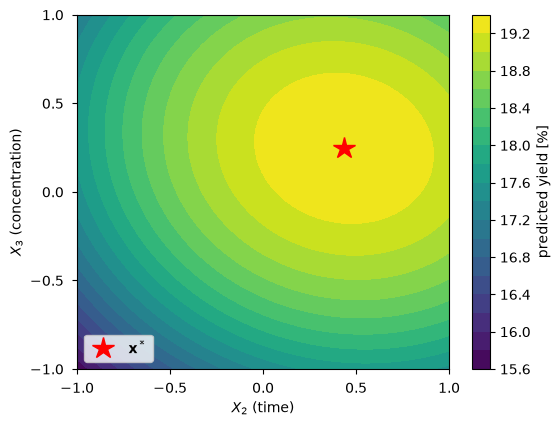

In [4]:
g = np.linspace(-1, 1, 60)
G2, G3 = np.meshgrid(g, g)
Yg = y_model(np.column_stack([np.ones(G2.size) * x_star[0], G2.ravel(), G3.ravel()])).reshape(G2.shape)
plt.figure(figsize=(6, 4.6))
cs = plt.contourf(G2, G3, Yg, 20, cmap="viridis")
plt.colorbar(cs, label="predicted yield [%]")
plt.plot(x_star[1], x_star[2], "r*", ms=16, label=r"$\mathbf{x}^*$")
plt.xticks([-1, -0.5, 0, 0.5, 1]); plt.yticks([-1, -0.5, 0, 0.5, 1]); plt.tick_params(pad=6)
plt.xlabel("$X_2$ (time)"); plt.ylabel("$X_3$ (concentration)"); plt.legend(loc="lower left")
plt.show()

**Check the math.** Write the model as $y=\theta_0+\mathbf{b}^T\mathbf{x}+\mathbf{x}^T\mathbf{A}\mathbf{x}$, with $\mathbf{b}=(\theta_1,\theta_2,\theta_3)$, the quadratic coefficients on the diagonal of $\mathbf{A}$ and half of the interaction coefficients off the diagonal. The gradient is $\nabla y=\mathbf{b}+2\mathbf{A}\mathbf{x}$ and the Hessian is $2\mathbf{A}$. At a constrained maximum, the gradient is zero for inputs inside their bounds and positive for an input at its upper bound.

In [5]:
b = theta_hat[1:4]
A = np.array([[theta_hat[4],     theta_hat[7]/2, theta_hat[8]/2],
              [theta_hat[7]/2,   theta_hat[5],   theta_hat[9]/2],
              [theta_hat[8]/2,   theta_hat[9]/2, theta_hat[6]]])
print("gradient at x_star:", np.round(b + 2 * A @ x_star, 3))
print("eigenvalues of the Hessian 2A:", np.round(np.linalg.eigvalsh(2 * A), 3), "(all negative: concave)")

gradient at x_star: [ 1.273 -0.    -0.   ]
eigenvalues of the Hessian 2A: [-2.652 -2.196 -1.611] (all negative: concave)


Uncertainty of the prediction at $\mathbf{x}^*$: $\mathbb{V}[y(\mathbf{x})]=\mathbf{x}^T\mathrm{Cov}[\hat{\theta}]\mathbf{x}$ with
$\mathrm{Cov}[\hat{\theta}]=\hat{\sigma}^2(\mathbf{X}^T\mathbf{X})^{-1}$.

In [6]:
eps_hat = y - X @ theta_hat
sigma_hat = np.sqrt(eps_hat @ eps_hat / (S - n_par))
Cov_theta = sigma_hat**2 * np.linalg.inv(X.T @ X)

**From parameters to prediction.** With $\mathbf{x}^*$ as the row of features at the optimum, the 95% confidence interval of the mean yield is

$$y(\mathbf{x}^*,\hat{\theta})\pm t_{0.975,\,S-10}\sqrt{\mathbb{V}[y(\mathbf{x}^*)]},$$

where $t_{0.975,S-10}$ is the Student quantile. This is the uncertainty of the model; a new measurement has in addition the noise variance $\hat{\sigma}^2$.

In [7]:
f_star = features(x_star)[0]
V_y = f_star @ Cov_theta @ f_star
t = stats.t.ppf(0.975, S - n_par)
m = f_star @ theta_hat
print(f"SD of the predicted yield = {np.sqrt(V_y):.3f} %")
print(f"95% confidence interval = [{m - t*np.sqrt(V_y):.2f}, {m + t*np.sqrt(V_y):.2f}] %")

SD of the predicted yield = 0.158 %
95% confidence interval = [19.02, 19.77] %


**Note:** The predicted optimum (100 C, 1.72 h, 0.225 %) has a yield of 19.4 %, above the best experiment (19.18 %), but the best experiment lies inside the confidence interval of the prediction: the model suggests the next experiment, it does not replace it.